<a href="https://colab.research.google.com/github/Lagnajit09/100x_AI_ML/blob/main/calibrated-typed-decision/TrainACalibratedModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **[1] — Install**

In [1]:
!pip install -q -U "transformers>=4.48" datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 108.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 18.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


## **[2] — Imports and GPU check**

In [2]:
import os, json, math, random, time, pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import transformers
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__, "| transformers", transformers.__version__)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU found: Runtime > Change runtime type > T4 GPU")

device: cuda | torch 2.11.0+cu130 | transformers 5.19.0
GPU: Tesla T4


## **[3] — Google Drive**

In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## **[4] — Settings**

In [5]:
SMOKE = False     # True: tiny practice run (a few minutes). False: the real experiment.

MODEL_NAME   = "answerdotai/ModernBERT-base"
DATASET_NAME = "m-lagnajit/calibrated-typed-decisions"
DATASET_REV  = "main"           # v2. v1 is still available as revision="v1.0"
# A NEW folder: the v1 folder holds finished v1 runs, which Cell 15 would otherwise load
OUT_DIR = "/content/drive/MyDrive/ctd_student_v2_smoke" if SMOKE else "/content/drive/MyDrive/ctd_student_v2"
os.makedirs(OUT_DIR, exist_ok=True)

RUNS = ["A", "B", "C", "D", "E"]
# A: right answers only            B: right answers, softened evenly
# C: the dataset's soft_label      D: a blend of A and C
# E: C, corrected wherever the teacher's top pick was wrong
SEED = 0

# Step 2: building the input
MAX_LEN        = 512            # longest sequence the student reads
MAX_Q_TOKENS   = 96             # v2: yes/no questions carry a description, PubMedQA a research question
MAX_OPT_TOKENS = 32             # v2: each option is "label: description"

# Step 6: training
BATCH_SIZE   = 16
EPOCHS       = 1 if SMOKE else 3
LR_BODY      = 3e-5             # small, careful steps for the pre-trained body
LR_HEAD      = 1e-3             # bigger steps for the brand-new scorer
WEIGHT_DECAY = 0.01
WARMUP_FRAC  = 0.10
CLIP_NORM    = 1.0
SMOOTHING    = 0.1              # Run B: how much belief to spread evenly
BLEND        = 0.5              # Run D: share of the target given to the human answer
USE_AMP      = True             # 16-bit math on the GPU; set False if the loss turns NaN
SAVE_WEIGHTS = not SMOKE        # save each run's best student to Drive (~600 MB each)

# Step 7: evaluation
N_BINS       = 10
N_BOOT       = 1000
MIN_FIT_ROWS = 30
SMOKE_SIZES  = {"train": 160, "validation": 80, "test": 80, "heldout": 40}

def amp_on():
    return USE_AMP and device == "cuda"

## **[5] — Load your dataset**

In [6]:
ds = load_dataset(DATASET_NAME, revision=DATASET_REV)
print(ds)
assert "heldout" in ds and "soft_label" in ds["train"].column_names, "this notebook needs v2 of the dataset"

def take(split):
    rows = list(ds[split])
    if SMOKE:
        rows = random.Random(SEED).sample(rows, min(SMOKE_SIZES[split], len(rows)))
    return rows

DATA = {split: take(split) for split in ["train", "validation", "test", "heldout"]}
print({split: len(rows) for split, rows in DATA.items()})
print(pd.DataFrame(DATA["train"]).groupby(["source", "type"]).size())
print("\ntraining targets come from:", pd.Series([r["soft_label_source"] for r in DATA["train"]]).value_counts().to_dict())

r = next(r for r in DATA["train"] if r["type"] == "choice")
print(json.dumps({k: r[k] for k in ["source", "type", "instructions", "state", "options",
                                    "option_descriptions", "gold", "soft_label", "soft_label_source"]},
                 indent=2, ensure_ascii=False)[:1400])

README.md:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 7.62MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  833kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/16995 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1799 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1797 [00:00<?, ? examples/s]

Generating heldout split:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'source', 'source_license', 'source_id', 'type', 'instructions', 'state', 'options', 'option_descriptions', 'candidate', 'gold', 'gold_index', 'display_perm', 'teacher_option_logprobs', 'teacher_temperature', 'teacher_shift', 'teacher_probs', 'teacher_letter_mass', 'human_probs', 'soft_label', 'soft_label_source'],
        num_rows: 16995
    })
    validation: Dataset({
        features: ['id', 'source', 'source_license', 'source_id', 'type', 'instructions', 'state', 'options', 'option_descriptions', 'candidate', 'gold', 'gold_index', 'display_perm', 'teacher_option_logprobs', 'teacher_temperature', 'teacher_shift', 'teacher_probs', 'teacher_letter_mass', 'human_probs', 'soft_label', 'soft_label_source'],
        num_rows: 1799
    })
    test: Dataset({
        features: ['id', 'source', 'source_license', 'source_id', 'type', 'instructions', 'state', 'options', 'option_descriptions', 'candidate', 'gold', 'gold_index', 'displ

## **[6] — Tokenizer and special tokens**

In [7]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
CLS, SEP, MASK, PAD = tok.cls_token_id, tok.sep_token_id, tok.mask_token_id, tok.pad_token_id
print({"[CLS]": CLS, "[SEP]": SEP, "[MASK]": MASK, "[PAD]": PAD})
assert None not in (CLS, SEP, MASK, PAD), "tokenizer is missing a special token"

config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.13M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

{'[CLS]': 50281, '[SEP]': 50282, '[MASK]': 50284, '[PAD]': 50283}


## **[7] — Tokenize every piece once**

In [8]:
def option_texts(row):
    """What the student reads for each option, in stored order. v2: 'label: description'."""
    if row["type"] == "noul":
        return ["no", "yes"]
    descs = row.get("option_descriptions") or [""] * len(row["options"])
    return [f"{o}: {d}" if d else o for o, d in zip(row["options"], descs)]

def pretokenize(rows):
    qs   = tok([r["instructions"] for r in rows], add_special_tokens=False)["input_ids"]
    txts = tok([" " + r["state"] for r in rows], add_special_tokens=False)["input_ids"]
    flat = [" " + o for r in rows for o in option_texts(r)]
    flat_ids = tok(flat, add_special_tokens=False)["input_ids"]
    k = 0
    for r, q, t in zip(rows, qs, txts):
        n = len(option_texts(r))
        r["q_ids"]   = q[:MAX_Q_TOKENS]
        r["opt_ids"] = [o[:MAX_OPT_TOKENS] for o in flat_ids[k:k + n]]
        r["txt_ids"] = t
        k += n

for split in DATA:
    pretokenize(DATA[split])

r = next(r for r in DATA["train"] if r["type"] == "choice")
print("question pieces:", tok.convert_ids_to_tokens(r["q_ids"]))
print("option pieces:  ", [tok.convert_ids_to_tokens(o) for o in r["opt_ids"]])

# How much room is left for the text, in the worst row of every split?
head = max(2 + len(r["q_ids"]) + sum(1 + len(o) for o in r["opt_ids"]) + 1
           for split in DATA for r in DATA[split])
print(f"longest question + options: {head} tokens -> the text always keeps at least {MAX_LEN - head}")

question pieces: ['Which', 'Ġintent', 'Ġbest', 'Ġdescribes', 'Ġthis', 'Ġrequest', 'Ġto', 'Ġa', 'Ġvirtual', 'Ġassistant', '?']
option pieces:   [['Ġmeeting', 'Ġschedule', ':', 'Ġasking', 'Ġabout', 'Ġscheduled', 'Ġmeetings', 'Ġand', 'Ġtheir', 'Ġtim', 'ings'], ['Ġroll', 'over', 'Ġ401', 'k', ':', 'Ġroll', 'over', 'Ġof', 'Ġ401', 'k', 'Ġfunds'], ['Ġtaxes', ':', 'Ġasking', 'Ġabout', 'Ġtax', 'Ġpayments', 'Ġand', 'Ġobligations'], ['Ġspending', 'Ġhistory', ':', 'Ġasking', 'Ġabout', 'Ġpast', 'Ġspending'], ['Ġaccount', 'Ġblocked', ':', 'Ġaccount', 'Ġaccess', 'Ġor', 'Ġtransaction', 'Ġfunctionality', 'Ġrestricted'], ['Ġrestaurant', 'Ġsuggestion', ':', 'Ġsuggestions', 'Ġfor', 'Ġrestaurants']]
longest question + options: 122 tokens -> the text always keeps at least 390


## **[8] — Build one input sequence**

In [9]:
def build_input(row, rng=None):
    """[CLS] question [SEP] [MASK] opt [MASK] opt ... [SEP] text [SEP]
    rng=None -> options in stored order (evaluation)
    rng      -> options in a random order (training), so position can't become a shortcut"""
    n = len(row["opt_ids"])
    perm = list(range(n))
    if rng is not None:
        rng.shuffle(perm)                  # shown slot d holds stored option perm[d]
    ids = [CLS] + row["q_ids"] + [SEP]
    marker_pos = []
    for c in perm:
        marker_pos.append(len(ids))        # this option's [MASK] lands here
        ids += [MASK] + row["opt_ids"][c]
    ids += [SEP]
    room = MAX_LEN - len(ids) - 1          # leave space for the final [SEP]
    ids += row["txt_ids"][:room] + [SEP]   # only the text can ever be cut
    return {"input_ids": ids, "marker_pos": marker_pos, "perm": perm}

ex = build_input(DATA["train"][0])
print(len(ex["input_ids"]), "tokens | markers at", ex["marker_pos"])
for p, piece in enumerate(tok.convert_ids_to_tokens(ex["input_ids"])[:40]):
    print(f"{p:3d}  {piece}{'   <- marker' if p in ex['marker_pos'] else ''}")

81 tokens | markers at [13, 25, 37, 46, 54, 64]
  0  [CLS]
  1  Which
  2  Ġintent
  3  Ġbest
  4  Ġdescribes
  5  Ġthis
  6  Ġrequest
  7  Ġto
  8  Ġa
  9  Ġvirtual
 10  Ġassistant
 11  ?
 12  [SEP]
 13  [MASK]   <- marker
 14  Ġmeeting
 15  Ġschedule
 16  :
 17  Ġasking
 18  Ġabout
 19  Ġscheduled
 20  Ġmeetings
 21  Ġand
 22  Ġtheir
 23  Ġtim
 24  ings
 25  [MASK]   <- marker
 26  Ġroll
 27  over
 28  Ġ401
 29  k
 30  :
 31  Ġroll
 32  over
 33  Ġof
 34  Ġ401
 35  k
 36  Ġfunds
 37  [MASK]   <- marker
 38  Ġtaxes
 39  :


## **[9] — Each run’s target**

In [10]:
def make_target(row, run):
    """The run's target, in stored order."""
    n, g = len(row["opt_ids"]), row["gold_index"]
    onehot = np.zeros(n)
    onehot[g] = 1.0
    if run == "A":                                   # 100% on the right answer
        return onehot
    if run == "B":                                   # 0.9 + 0.1/n on the right answer, 0.1/n elsewhere
        t = np.full(n, SMOOTHING / n)
        t[g] += 1.0 - SMOOTHING
        return t
    soft = np.array(row["soft_label"], dtype=float)  # rater votes (GoEmotions) or calibrated teacher
    soft = soft / soft.sum()
    if run == "C":
        return soft
    if run == "D":                                   # part human answer, part soft label
        return BLEND * onehot + (1 - BLEND) * soft
    if run == "E":                                   # fix the teacher's wrong top picks, keep its shape
        if row["soft_label_source"] == "teacher":
            k = int(soft.argmax())
            if k != g:
                soft[k], soft[g] = soft[g], soft[k]  # the right answer gets the teacher's top value
        return soft
    raise ValueError(run)

# Show all five on a row where the teacher's top pick was wrong
wrong = [r for r in DATA["train"]
         if r["soft_label_source"] == "teacher" and int(np.argmax(r["soft_label"])) != r["gold_index"]]
r = wrong[0] if wrong else DATA["train"][0]
print("options:", option_texts(r), "\nright answer:", r["gold"])
for run in RUNS:
    print(f"target {run}:", np.round(make_target(r, run), 3))
teacher_rows = sum(r["soft_label_source"] == "teacher" for r in DATA["train"])
print(f"\nRun E changes {len(wrong)} of {teacher_rows} teacher-labelled training rows "
      f"({len(wrong) / max(1, teacher_rows):.1%}); rater-labelled GoEmotions rows are left as they are")

options: ['timezone: time zones of locations around the world', 'pay bill: request to pay a bill', "change user name: change user's name in system settings", 'date: request for current or future dates', 'travel alert: travel advisories and safety warnings', 'directions: requests for travel or location directions', 'traffic: traffic conditions and forecasts', 'distance: distance travel time estimates'] 
right answer: distance
target A: [0. 0. 0. 0. 0. 0. 0. 1.]
target B: [0.012 0.012 0.012 0.012 0.012 0.012 0.012 0.912]
target C: [0.001 0.001 0.001 0.001 0.002 0.772 0.005 0.216]
target D: [0.001 0.001 0.001 0.001 0.001 0.386 0.002 0.608]
target E: [0.001 0.001 0.001 0.001 0.002 0.216 0.005 0.772]

Run E changes 1391 of 13996 teacher-labelled training rows (9.9%); rater-labelled GoEmotions rows are left as they are


## **[10] — Build a batch**

In [11]:
def make_batch(rows, run=None, rng=None):
    items = [build_input(r, rng) for r in rows]
    B = len(rows)
    L = max(len(it["input_ids"]) for it in items)       # longest sequence in this batch
    K = max(len(it["marker_pos"]) for it in items)      # most options in this batch
    input_ids   = torch.full((B, L), PAD, dtype=torch.long)
    attn        = torch.zeros((B, L), dtype=torch.long)
    marker_pos  = torch.zeros((B, K), dtype=torch.long) # empty slots point at position 0
    option_mask = torch.zeros((B, K), dtype=torch.bool)
    target      = torch.zeros((B, K), dtype=torch.float)
    perms = []
    for b, (row, it) in enumerate(zip(rows, items)):
        n_tok, k = len(it["input_ids"]), len(it["marker_pos"])
        input_ids[b, :n_tok] = torch.tensor(it["input_ids"])
        attn[b, :n_tok] = 1
        marker_pos[b, :k] = torch.tensor(it["marker_pos"])
        option_mask[b, :k] = True
        if run is not None:
            t = make_target(row, run)
            target[b, :k] = torch.tensor(t[it["perm"]], dtype=torch.float)   # into shown order
        perms.append(it["perm"])
    return {"input_ids": input_ids, "attention_mask": attn, "marker_pos": marker_pos,
            "option_mask": option_mask, "target": target, "perms": perms}

demo = make_batch(DATA["train"][:8], run="C", rng=random.Random(0))
for k, v in demo.items():
    if torch.is_tensor(v):
        print(f"{k:15s} shape {tuple(v.shape)}")
print("option_mask:\n", demo["option_mask"].int())

input_ids       shape (8, 102)
attention_mask  shape (8, 102)
marker_pos      shape (8, 8)
option_mask     shape (8, 8)
target          shape (8, 8)
option_mask:
 tensor([[1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0, 0, 0, 0]], dtype=torch.int32)


## **[11] — The student**

In [12]:
MODEL_INPUTS = ["input_ids", "attention_mask", "marker_pos", "option_mask"]

class Student(nn.Module):
    def __init__(self, name):
        super().__init__()
        try:
            self.body = AutoModel.from_pretrained(name, reference_compile=False)
        except (TypeError, ValueError):
            self.body = AutoModel.from_pretrained(name)
        self.body = self.body.float()
        self.scorer = nn.Linear(self.body.config.hidden_size, 1)        # 768 weights + 1 bias

    def forward(self, input_ids, attention_mask, marker_pos, option_mask):
        h = self.body(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state  # (B, L, 768)
        idx = marker_pos.unsqueeze(-1).expand(-1, -1, h.size(-1))                           # (B, K, 768)
        markers = torch.gather(h, 1, idx)                                                   # (B, K, 768)
        scores = self.scorer(markers).squeeze(-1)                                           # (B, K)
        return scores.masked_fill(~option_mask, float("-inf"))                              # block empty slots

torch.manual_seed(SEED)
_student = Student(MODEL_NAME)
print(f"body:   {sum(p.numel() for p in _student.body.parameters()):,} numbers")
print(f"scorer: {sum(p.numel() for p in _student.scorer.parameters()):,} numbers")
with torch.no_grad():
    s = _student(**{k: demo[k] for k in MODEL_INPUTS})
print("scores shape:", tuple(s.shape))
print("untrained chances, row 0:", torch.softmax(s[0], dim=-1).numpy().round(3))
del _student

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


body:   149,014,272 numbers
scorer: 769 numbers
scores shape: (8, 8)
untrained chances, row 0: [0.234 0.185 0.17  0.151 0.133 0.128 0.    0.   ]


## **[12] — The loss**

In [13]:
def soft_cross_entropy(scores, target, option_mask):
    log_p = torch.log_softmax(scores.float(), dim=-1)
    log_p = log_p.masked_fill(~option_mask, 0.0)        # empty slots count as 0, not 0 × (−∞)
    return -(target * log_p).sum(dim=-1).mean()

# Check against Step 5's worked example
s = torch.tensor([[0.12, 2.35, 1.06, 0.06]])
m = torch.ones(1, 4, dtype=torch.bool)
for run, t in [("A", [0, 1, 0, 0]), ("B", [0.025, 0.925, 0.025, 0.025]), ("C", [0.08, 0.68, 0.18, 0.06])]:
    print(run, round(soft_cross_entropy(s, torch.tensor([t], dtype=torch.float), m).item(), 3))

A 0.395
B 0.54
C 0.943


## **[13] — Predicting and measuring**

In [14]:
@torch.no_grad()
def predict_scores(model, rows, bs=64):
    """Raw scores for every row, in stored order: one numpy array per row."""
    model.eval()
    out = []
    for i in range(0, len(rows), bs):
        batch = make_batch(rows[i:i + bs])                     # no rng: stored order
        feed = {k: batch[k].to(device) for k in MODEL_INPUTS}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on()):
            s = model(**feed).float().cpu().numpy()
        for b, perm in enumerate(batch["perms"]):
            row_scores = np.empty(len(perm))
            row_scores[perm] = s[b, :len(perm)]                # shown order -> stored order
            out.append(row_scores)
    model.train()
    return out

def softmax_np(z):
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

def per_row(probs_list, rows):
    """Confidence, right/wrong, and log-loss penalty for each question."""
    conf    = np.array([p.max() for p in probs_list])
    correct = np.array([float(p.argmax() == r["gold_index"]) for p, r in zip(probs_list, rows)])
    nll     = np.array([-np.log(max(p[r["gold_index"]], 1e-12)) for p, r in zip(probs_list, rows)])
    return conf, correct, nll

def ece_from(conf, correct, idx=None):
    if idx is not None:
        conf, correct = conf[idx], correct[idx]
    bins  = np.minimum((conf * N_BINS).astype(int), N_BINS - 1)
    said  = np.bincount(bins, weights=conf,    minlength=N_BINS)   # total confidence per group
    right = np.bincount(bins, weights=correct, minlength=N_BINS)   # total right answers per group
    return float(np.abs(right - said).sum() / len(conf))

def metrics(probs_list, rows):
    conf, correct, nll = per_row(probs_list, rows)
    return {"accuracy": correct.mean(), "ECE": ece_from(conf, correct), "log loss": nll.mean()}

## **[14] — One complete training run**

In [15]:
def lr_factor(step, total, warmup):
    """Warmup to 1.0, then a straight fall to 0 (Step 6e)."""
    if step < warmup:
        return (step + 1) / warmup
    return max(0.0, (total - step) / max(1, total - warmup))

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

def train_run(run):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    model = Student(MODEL_NAME).to(device)
    model.train()
    optimizer = torch.optim.AdamW([
        {"params": model.body.parameters(),   "lr": LR_BODY},
        {"params": model.scorer.parameters(), "lr": LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)

    train = DATA["train"]
    steps_per_epoch = math.ceil(len(train) / BATCH_SIZE)
    total  = steps_per_epoch * EPOCHS
    warmup = max(1, int(WARMUP_FRAC * total))
    schedule = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: lr_factor(s, total, warmup))
    scaler = make_scaler(amp_on())
    print(f"run {run}: {len(train)} questions, {steps_per_epoch} steps per epoch, "
          f"{total} steps in total, warmup {warmup}")

    best, history, step = {"val_loss": float("inf")}, [], 0
    for epoch in range(EPOCHS):
        rng = random.Random(SEED * 1000 + epoch)           # same shuffle and swaps in every run
        order = list(range(len(train)))
        rng.shuffle(order)
        t0, losses = time.time(), []
        for i in range(0, len(order), BATCH_SIZE):
            batch = make_batch([train[j] for j in order[i:i + BATCH_SIZE]], run=run, rng=rng)
            feed = {k: batch[k].to(device) for k in MODEL_INPUTS}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on()):
                scores = model(**feed)                                          # Steps 2-4: guess
            loss = soft_cross_entropy(scores, batch["target"].to(device), feed["option_mask"])  # Step 5
            if not torch.isfinite(loss):
                raise RuntimeError("Loss became NaN or infinite. Set USE_AMP = False in Cell 4, "
                                   "rerun from Cell 4, and train again.")
            scaler.scale(loss).backward()                                       # slopes
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)       # safety belt
            scaler.step(optimizer)                                              # nudge downhill
            scaler.update()
            schedule.step()
            optimizer.zero_grad(set_to_none=True)
            losses.append(loss.item())
            step += 1
            if step % 50 == 0:
                print(f"  epoch {epoch + 1} | step {step}/{total} | train loss {np.mean(losses[-50:]):.4f} "
                      f"| body lr {schedule.get_last_lr()[0]:.1e}")

        # Validation check: real answers, the same scoring for every run (Step 6g)
        val = metrics([softmax_np(s) for s in predict_scores(model, DATA["validation"])], DATA["validation"])
        history.append({"epoch": epoch + 1, "train_loss": float(np.mean(losses)),
                        "val_loss": float(val["log loss"]), "val_accuracy": float(val["accuracy"]),
                        "val_ECE": float(val["ECE"])})
        print(f"run {run} | epoch {epoch + 1} done in {time.time() - t0:.0f}s | train loss {np.mean(losses):.4f} "
              f"| val loss {val['log loss']:.4f} | val acc {val['accuracy']:.3f} | val ECE {val['ECE']:.3f}")
        if val["log loss"] < best["val_loss"]:
            best = {"val_loss": val["log loss"], "epoch": epoch + 1,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            print(f"  -> new best student (epoch {epoch + 1})")

    model.load_state_dict(best["state"])
    print(f"run {run}: keeping epoch {best['epoch']}")
    preds = {"run": run, "best_epoch": best["epoch"], "history": history,
             "validation": predict_scores(model, DATA["validation"]),
             "test": predict_scores(model, DATA["test"]),
             "heldout": predict_scores(model, DATA["heldout"])}
    with open(f"{OUT_DIR}/preds_{run}.pkl", "wb") as f:
        pickle.dump(preds, f)
    if SAVE_WEIGHTS:
        torch.save(best["state"], f"{OUT_DIR}/student_{run}.pt")
    del model, optimizer, best
    torch.cuda.empty_cache()
    return preds

## **[15] — Train the three students**

In [16]:
PREDS = {}
for run in RUNS:
    path = f"{OUT_DIR}/preds_{run}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as f:
            PREDS[run] = pickle.load(f)
        print(f"run {run}: already trained, loaded from Drive (kept epoch {PREDS[run]['best_epoch']})")
    else:
        print(f"\n========== training run {run} ==========")
        PREDS[run] = train_run(run)


========== training run A ==========


Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


run A: 16995 questions, 1063 steps per epoch, 3189 steps in total, warmup 318
  epoch 1 | step 50/3189 | train loss 1.2237 | body lr 4.8e-06
  epoch 1 | step 100/3189 | train loss 1.1463 | body lr 9.5e-06
  epoch 1 | step 150/3189 | train loss 1.0919 | body lr 1.4e-05
  epoch 1 | step 200/3189 | train loss 0.7893 | body lr 1.9e-05
  epoch 1 | step 250/3189 | train loss 0.5270 | body lr 2.4e-05
  epoch 1 | step 300/3189 | train loss 0.4945 | body lr 2.8e-05
  epoch 1 | step 350/3189 | train loss 0.5069 | body lr 3.0e-05
  epoch 1 | step 400/3189 | train loss 0.4526 | body lr 2.9e-05
  epoch 1 | step 450/3189 | train loss 0.3555 | body lr 2.9e-05
  epoch 1 | step 500/3189 | train loss 0.3448 | body lr 2.8e-05
  epoch 1 | step 550/3189 | train loss 0.3740 | body lr 2.8e-05
  epoch 1 | step 600/3189 | train loss 0.3230 | body lr 2.7e-05
  epoch 1 | step 650/3189 | train loss 0.2861 | body lr 2.7e-05
  epoch 1 | step 700/3189 | train loss 0.3720 | body lr 2.6e-05
  epoch 1 | step 750/3189 |

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

...

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


run D: 16995 questions, 1063 steps per epoch, 3189 steps in total, warmup 318
  epoch 1 | step 50/3189 | train loss 1.2240 | body lr 4.8e-06
  epoch 1 | step 100/3189 | train loss 1.1564 | body lr 9.5e-06
  epoch 1 | step 150/3189 | train loss 1.0717 | body lr 1.4e-05
  epoch 1 | step 200/3189 | train loss 0.7429 | body lr 1.9e-05
  epoch 1 | step 250/3189 | train loss 0.5812 | body lr 2.4e-05
  epoch 1 | step 300/3189 | train loss 0.5382 | body lr 2.8e-05
  epoch 1 | step 350/3189 | train loss 0.5219 | body lr 3.0e-05
  epoch 1 | step 400/3189 | train loss 0.5080 | body lr 2.9e-05
  epoch 1 | step 450/3189 | train loss 0.4610 | body lr 2.9e-05
  epoch 1 | step 500/3189 | train loss 0.4626 | body lr 2.8e-05
  epoch 1 | step 550/3189 | train loss 0.4505 | body lr 2.8e-05
  epoch 1 | step 600/3189 | train loss 0.4032 | body lr 2.7e-05
  epoch 1 | step 650/3189 | train loss 0.4107 | body lr 2.7e-05
  epoch 1 | step 700/3189 | train loss 0.4315 | body lr 2.6e-05
  epoch 1 | step 750/3189 |

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


run E: 16995 questions, 1063 steps per epoch, 3189 steps in total, warmup 318
  epoch 1 | step 50/3189 | train loss 1.2244 | body lr 4.8e-06
  epoch 1 | step 100/3189 | train loss 1.1702 | body lr 9.5e-06
  epoch 1 | step 150/3189 | train loss 1.0919 | body lr 1.4e-05
  epoch 1 | step 200/3189 | train loss 0.7664 | body lr 1.9e-05
  epoch 1 | step 250/3189 | train loss 0.6388 | body lr 2.4e-05
  epoch 1 | step 300/3189 | train loss 0.5947 | body lr 2.8e-05
  epoch 1 | step 350/3189 | train loss 0.5898 | body lr 3.0e-05
  epoch 1 | step 400/3189 | train loss 0.6022 | body lr 2.9e-05
  epoch 1 | step 450/3189 | train loss 0.5258 | body lr 2.9e-05
  epoch 1 | step 500/3189 | train loss 0.5496 | body lr 2.8e-05
  epoch 1 | step 550/3189 | train loss 0.5320 | body lr 2.8e-05
  epoch 1 | step 600/3189 | train loss 0.5214 | body lr 2.7e-05
  epoch 1 | step 650/3189 | train loss 0.5221 | body lr 2.7e-05
  epoch 1 | step 700/3189 | train loss 0.5358 | body lr 2.6e-05
  epoch 1 | step 750/3189 |

## **[16] — Give every student a dial**

In [17]:
GRID   = np.exp(np.linspace(np.log(0.25), np.log(20.0), 200))   # dial settings to try
B_GRID = np.linspace(-8.0, 8.0, 321)                             # nudge sizes to try (yes/no only)

def probs_with_dial(scores, qtype, T, b):
    z = np.array(scores, dtype=float) / T
    if qtype == "noul":
        z[1] += b
    return softmax_np(z)

def fit_dial(scores, rows):
    """The (dial, nudge) with the lowest validation log loss. Nudge only for yes/no."""
    if rows[0]["type"] == "noul":
        gap = np.array([s[1] - s[0] for s in scores])
        y   = np.array([r["gold_index"] for r in rows])
        with np.errstate(over="ignore"):
            z = gap[None, None, :] / GRID[:, None, None] + B_GRID[None, :, None]
            p = 1.0 / (1.0 + np.exp(-z))
        pen = -(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)).mean(axis=2)
        i, j = np.unravel_index(np.argmin(pen), pen.shape)
        return float(GRID[i]), float(B_GRID[j])
    losses = [np.mean([-np.log(probs_with_dial(s, "choice", T, 0.0)[r["gold_index"]] + 1e-12)
                       for s, r in zip(scores, rows)]) for T in GRID]
    return float(GRID[int(np.argmin(losses))]), 0.0

def group_of(row):
    return (row["source"], row["type"])

def fit_dials(val_scores, val_rows):
    pooled = {}
    for qtype in ["choice", "noul"]:
        pairs = [(s, r) for s, r in zip(val_scores, val_rows) if r["type"] == qtype]
        pooled[qtype] = fit_dial(*zip(*pairs)) if len(pairs) >= MIN_FIT_ROWS else (1.0, 0.0)
    dials = {}
    for g in {group_of(r) for r in val_rows}:
        pairs = [(s, r) for s, r in zip(val_scores, val_rows) if group_of(r) == g]
        dials[g] = fit_dial(*zip(*pairs)) if len(pairs) >= MIN_FIT_ROWS else pooled[g[1]]
    return dials, pooled

def apply_dials(scores, rows, dials, pooled):
    return [probs_with_dial(s, r["type"], *dials.get(group_of(r), pooled[r["type"]]))
            for s, r in zip(scores, rows)]

TEST, HELD = DATA["test"], DATA["heldout"]
PROBS, PROBS_H = {}, {}             # name -> chances for every test / held-out question
for run in RUNS:
    dials, pooled = fit_dials(PREDS[run]["validation"], DATA["validation"])
    PROBS[f"Student {run}"]        = [softmax_np(s) for s in PREDS[run]["test"]]
    PROBS[f"Student {run} + dial"] = apply_dials(PREDS[run]["test"], TEST, dials, pooled)
    # Held-out's source never appears in validation, so apply_dials falls back to the POOLED dial:
    # fitted on validation questions from all six sources, before any PubMedQA answer is seen.
    PROBS_H[f"Student {run}"]        = [softmax_np(s) for s in PREDS[run]["heldout"]]
    PROBS_H[f"Student {run} + dial"] = apply_dials(PREDS[run]["heldout"], HELD, dials, pooled)
    print(f"Student {run} dials:", {f"{g[0].split('/')[-1]}/{g[1]}": (round(T, 2), round(b, 2))
                                    for g, (T, b) in sorted(dials.items())},
          f"| pooled choice dial (used for held-out): {pooled['choice'][0]:.2f}")
PROBS["Teacher"]   = [np.array(r["teacher_probs"]) / np.sum(r["teacher_probs"]) for r in TEST]
PROBS_H["Teacher"] = [np.array(r["teacher_probs"]) / np.sum(r["teacher_probs"]) for r in HELD]

Student A dials: {'scicite/choice': (1.36, 0.0), 'scicite/noul': (1.3, 0.8), 'clinc_oos/choice': (0.7, 0.0), 'clinc_oos/noul': (1.07, 0.25), 'go_emotions/choice': (1.77, 0.0), 'go_emotions/noul': (1.49, 1.1), 'amazon_massive_intent/choice': (1.36, 0.0), 'amazon_massive_intent/noul': (1.19, 0.2), 'amazon_polarity/choice': (1.66, 0.0), 'amazon_polarity/noul': (0.96, -0.85), 'banking77/choice': (1.42, 0.0), 'banking77/noul': (1.55, -0.95)} | pooled choice dial (used for held-out): 1.46
Student B dials: {'scicite/choice': (1.0, 0.0), 'scicite/noul': (1.22, -0.1), 'clinc_oos/choice': (0.53, 0.0), 'clinc_oos/noul': (0.63, 1.05), 'go_emotions/choice': (0.9, 0.0), 'go_emotions/noul': (0.84, 1.15), 'amazon_massive_intent/choice': (0.86, 0.0), 'amazon_massive_intent/noul': (0.94, 0.35), 'amazon_polarity/choice': (0.67, 0.0), 'amazon_polarity/noul': (0.25, -6.95), 'banking77/choice': (0.74, 0.0), 'banking77/noul': (1.02, 0.15)} | pooled choice dial (used for held-out): 0.82
Student C dials: {'sci

## **[17] — The results tables**

In [18]:
LABELS = {"A": "right answers only", "B": "softened evenly", "C": "soft_label",
          "D": f"{BLEND:.0%} human answer + soft_label", "E": "soft_label, teacher mistakes corrected"}

def results_table(P, rows, teacher_label):
    out = []
    for run in RUNS:
        raw  = metrics(P[f"Student {run}"], rows)
        dial = metrics(P[f"Student {run} + dial"], rows)
        out.append({"model": f"Student {run} ({LABELS[run]})", "kept epoch": PREDS[run]["best_epoch"],
                    "accuracy": raw["accuracy"], "ECE": raw["ECE"], "log loss": raw["log loss"],
                    "accuracy after dial": dial["accuracy"], "ECE after dial": dial["ECE"],
                    "log loss after dial": dial["log loss"]})
    t = metrics(P["Teacher"], rows)
    out.append({"model": teacher_label, "accuracy": t["accuracy"], "ECE": t["ECE"], "log loss": t["log loss"]})
    return pd.DataFrame(out).round(3)

print(f"TEST: the six sources the students trained on ({len(TEST)} questions)")
results = results_table(PROBS, TEST, "Teacher (dial + nudge)")
display(results)
results.to_csv(f"{OUT_DIR}/results_test.csv", index=False)

print(f"\nHELD-OUT PubMedQA: never trained on ({len(HELD)} questions; dials pooled from validation)")
results_h = results_table(PROBS_H, HELD, "Teacher (as-is, no dial)")
display(results_h)
results_h.to_csv(f"{OUT_DIR}/results_heldout.csv", index=False)

breakdown = []
for g in sorted({group_of(r) for r in TEST}):
    idx  = [i for i, r in enumerate(TEST) if group_of(r) == g]
    sub  = [TEST[i] for i in idx]
    line = {"source": g[0].split("/")[-1], "type": g[1], "n": len(idx)}
    for name, short in [(f"Student {r}", r) for r in RUNS] + [("Teacher", "teacher")]:
        m = metrics([PROBS[name][i] for i in idx], sub)
        line[f"acc {short}"] = m["accuracy"]
        line[f"ECE {short}"] = m["ECE"]
    breakdown.append(line)
breakdown = pd.DataFrame(breakdown).round(3)
display(breakdown)
breakdown.to_csv(f"{OUT_DIR}/results_by_source.csv", index=False)

TEST: the six sources the students trained on (1797 questions)


,model,kept epoch,accuracy,ECE,log loss,accuracy after dial,ECE after dial,log loss after dial
0,Student A (right answers only),1.0,0.910,0.039,0.298,0.908,0.018,0.268
1,Student B (softened evenly),3.0,0.918,0.035,0.291,0.917,0.025,0.322
2,Student C (soft_label),2.0,0.896,0.046,0.323,0.900,0.019,0.340
3,Student D (50% human answer + soft_label),2.0,0.920,0.026,0.247,0.922,0.015,0.262
4,"Student E (soft_label, teacher mistakes correc...",2.0,0.917,0.069,0.280,0.919,0.016,0.271
5,Teacher (dial + nudge),NaN,0.843,0.023,0.448,NaN,NaN,NaN



HELD-OUT PubMedQA: never trained on (1000 questions; dials pooled from validation)


,model,kept epoch,accuracy,ECE,log loss,accuracy after dial,ECE after dial,log loss after dial
0,Student A (right answers only),1.0,0.538,0.049,0.977,0.538,0.097,0.997
1,Student B (softened evenly),3.0,0.585,0.066,0.943,0.585,0.109,0.957
2,Student C (soft_label),2.0,0.580,0.071,0.954,0.580,0.027,0.943
3,Student D (50% human answer + soft_label),2.0,0.548,0.090,1.021,0.548,0.064,1.017
4,"Student E (soft_label, teacher mistakes correc...",2.0,0.605,0.166,0.982,0.605,0.107,0.946
5,"Teacher (as-is, no dial)",NaN,0.647,0.286,2.325,NaN,NaN,NaN


,source,type,n,acc A,ECE A,acc B,ECE B,acc C,ECE C,acc D,ECE D,acc E,ECE E,acc teacher,ECE teacher
0,scicite,choice,214,0.813,0.120,0.813,0.079,0.794,0.051,0.841,0.040,0.836,0.080,0.799,0.030
1,scicite,noul,86,0.907,0.052,0.953,0.067,0.860,0.169,0.895,0.112,0.849,0.193,0.744,0.067
2,clinc_oos,choice,202,0.975,0.011,0.960,0.067,0.916,0.027,0.965,0.024,0.970,0.033,0.896,0.067
3,clinc_oos,noul,98,0.878,0.080,0.857,0.060,0.857,0.074,0.908,0.055,0.888,0.097,0.867,0.038
4,go_emotions,choice,216,0.838,0.077,0.861,0.039,0.884,0.160,0.875,0.079,0.870,0.174,0.569,0.088
5,go_emotions,noul,84,0.881,0.073,0.952,0.067,0.833,0.126,0.881,0.083,0.857,0.170,0.738,0.110
6,amazon_massive_intent,choice,212,0.958,0.024,0.962,0.071,0.939,0.057,0.972,0.043,0.958,0.058,0.901,0.028
7,amazon_massive_intent,noul,85,0.941,0.054,0.953,0.052,0.906,0.064,0.953,0.063,0.918,0.075,0.871,0.092
8,amazon_polarity,choice,190,0.942,0.048,0.953,0.024,0.958,0.035,0.937,0.029,0.947,0.036,0.963,0.020
9,amazon_polarity,noul,110,0.918,0.074,0.918,0.027,0.927,0.054,0.927,0.062,0.945,0.056,0.955,0.022


## **[18] — Real difference or luck?**

In [19]:
def make_boot(P, rows):
    """Bootstrap for one split: every model is scored on the SAME 1,000 redraws."""
    N = len(rows)
    idx_all = np.random.default_rng(SEED).integers(0, N, size=(N_BOOT, N))
    stats, cache = {name: per_row(P[name], rows) for name in P}, {}
    def boot(name, measure):
        if (name, measure) not in cache:
            conf, correct, nll = stats[name]
            if measure == "ECE":
                cache[name, measure] = np.array([ece_from(conf, correct, idx) for idx in idx_all])
            elif measure == "log loss":
                cache[name, measure] = np.array([nll[idx].mean() for idx in idx_all])
            else:
                cache[name, measure] = np.array([correct[idx].mean() for idx in idx_all])
        return cache[name, measure]
    return boot

# Every student gets its dial here: the dial is free, so "+ dial" is the fair comparison.
lines = []
for split_name, P, rows in [("test", PROBS, TEST), ("heldout", PROBS_H, HELD)]:
    boot = make_boot(P, rows)
    for cand in ["C", "D", "E"]:
        for base in ["A", "B"]:
            for measure, lower_is_better in [("accuracy", False), ("ECE", True), ("log loss", True)]:
                c = boot(f"Student {cand} + dial", measure)
                o = boot(f"Student {base} + dial", measure)
                diff = (o - c) if lower_is_better else (c - o)      # positive = candidate better
                lo, hi = np.percentile(diff, [2.5, 97.5])
                lines.append({"split": split_name, "comparison": f"{cand} vs {base}", "measure": measure,
                              "candidate better in": f"{int((diff > 0).sum())}/{N_BOOT}",
                              "average gap": round(float(diff.mean()), 4),
                              "95% range": f"[{lo:+.4f}, {hi:+.4f}]",
                              "verdict": f"{cand} better" if lo > 0 else
                                         (f"{cand} worse" if hi < 0 else "too close to call")})
boot_df = pd.DataFrame(lines)
display(boot_df)
boot_df.to_csv(f"{OUT_DIR}/bootstrap.csv", index=False)

,split,comparison,measure,candidate better in,average gap,95% range,verdict
0,test,C vs A,accuracy,116/1000,-0.0078,"[-0.0211, +0.0056]",too close to call
1,test,C vs A,ECE,386/1000,-0.0016,"[-0.0138, +0.0112]",too close to call
2,test,C vs A,log loss,0/1000,-0.0716,"[-0.1198, -0.0261]",C worse
3,test,C vs B,accuracy,4/1000,-0.0166,"[-0.0301, -0.0033]",C worse
4,test,C vs B,ECE,726/1000,0.0035,"[-0.0090, +0.0147]",too close to call
5,test,C vs B,log loss,226/1000,-0.0169,"[-0.0615, +0.0247]",too close to call
6,test,D vs A,accuracy,992/1000,0.0140,"[+0.0033, +0.0251]",D better
7,test,D vs A,ECE,715/1000,0.0034,"[-0.0071, +0.0152]",too close to call
8,test,D vs A,log loss,690/1000,0.0068,"[-0.0236, +0.0350]",too close to call
9,test,D vs B,accuracy,826/1000,0.0052,"[-0.0050, +0.0156]",too close to call


## **[19] — Reliability diagrams**

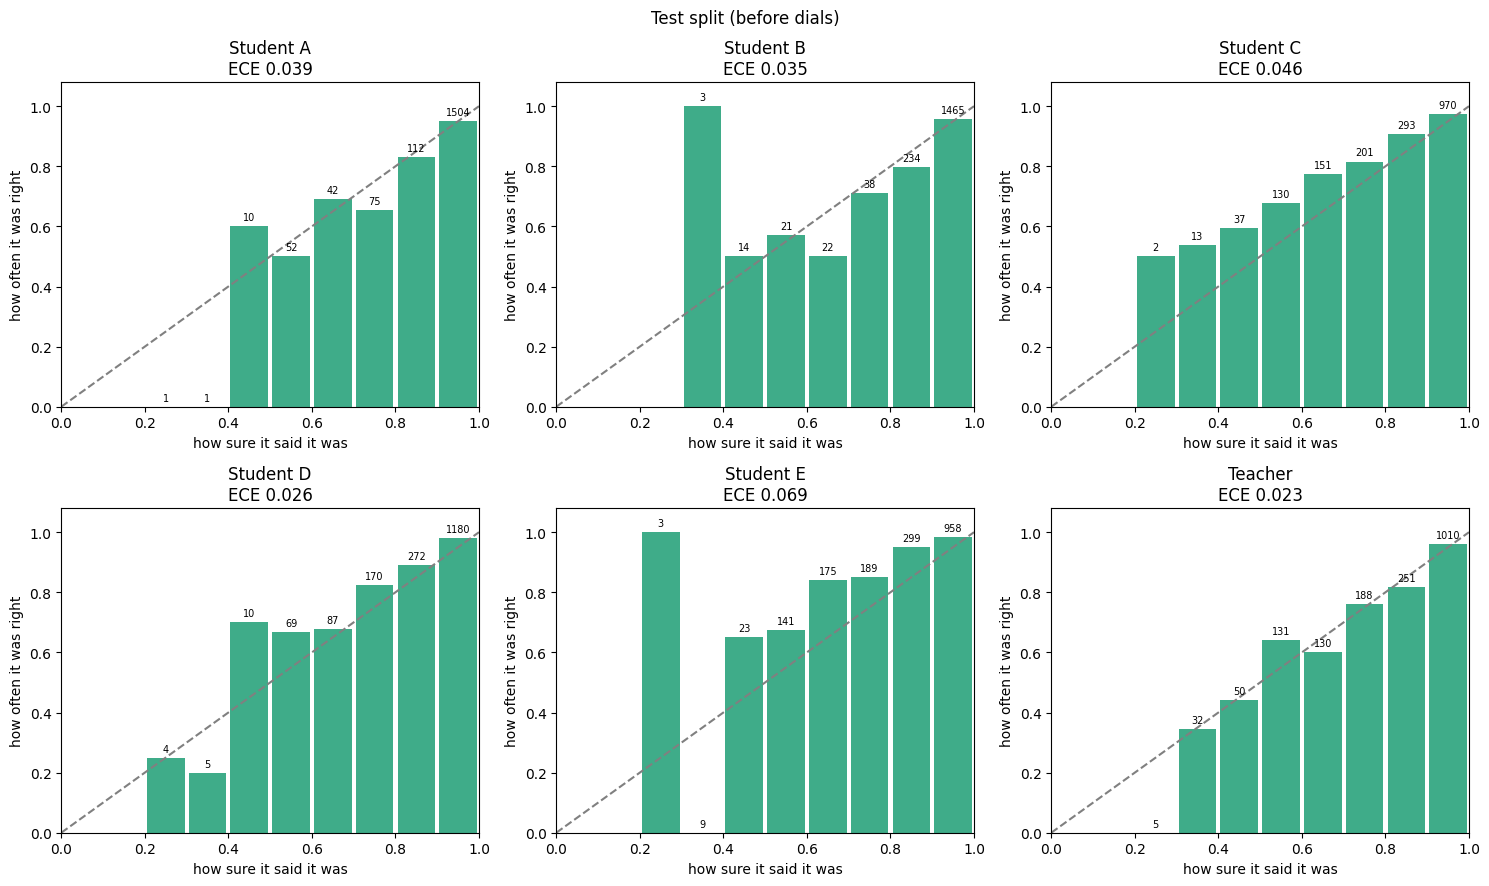

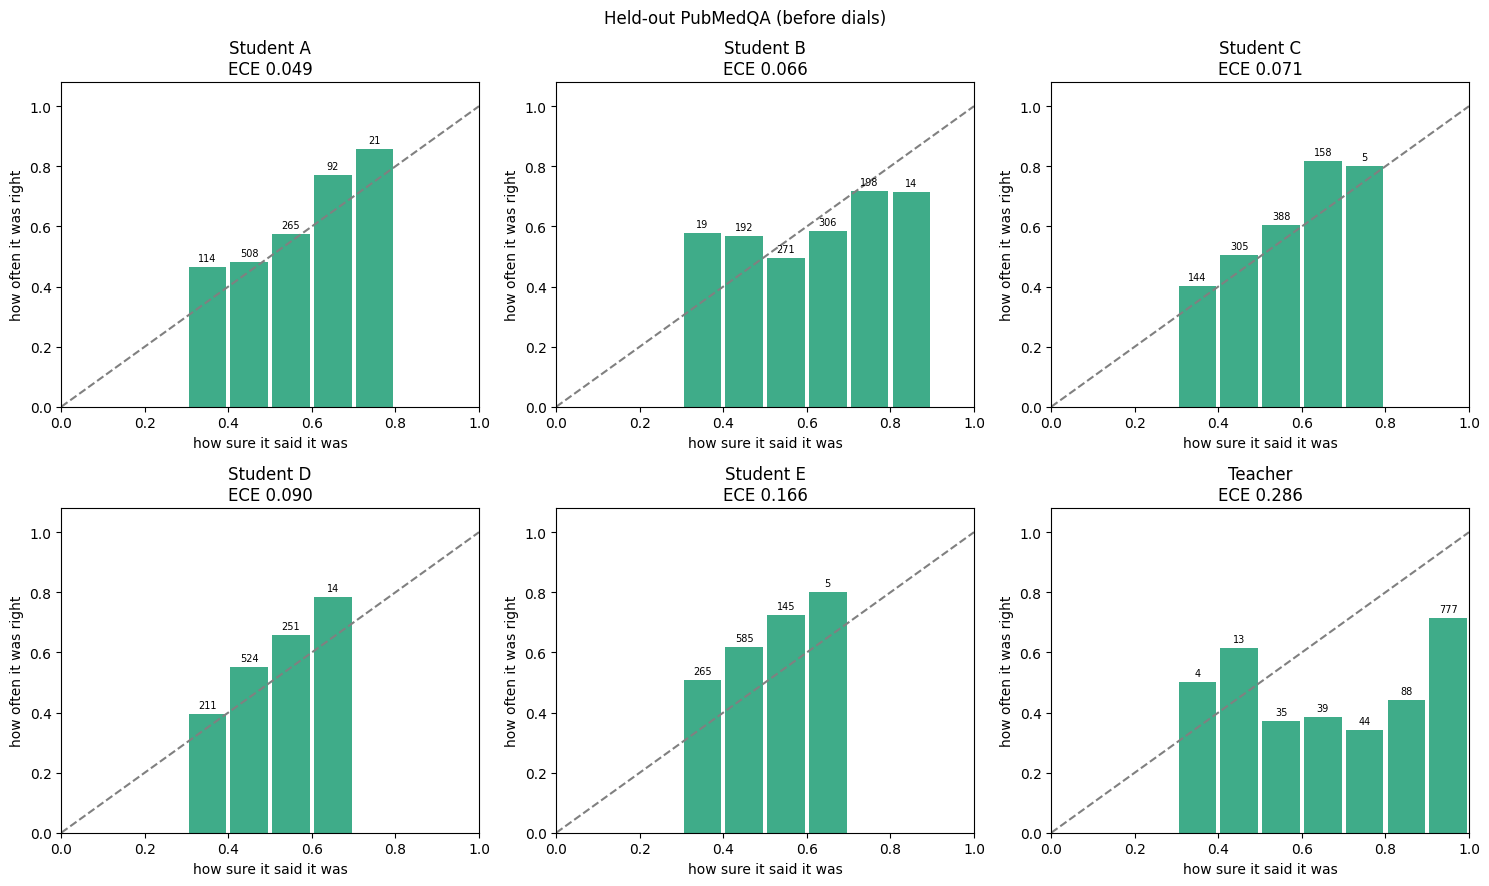

In [20]:
def reliability(ax, probs, rows, title):
    conf, correct, _ = per_row(probs, rows)
    bins = np.minimum((conf * N_BINS).astype(int), N_BINS - 1)
    for b in range(N_BINS):
        m = bins == b
        if m.any():
            center = (b + 0.5) / N_BINS
            ax.bar(center, correct[m].mean(), width=0.9 / N_BINS, color="#1D9E75", alpha=0.85)
            ax.text(center, correct[m].mean() + 0.02, str(int(m.sum())), ha="center", fontsize=7)
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(xlim=(0, 1), ylim=(0, 1.08), xlabel="how sure it said it was", ylabel="how often it was right",
           title=f"{title}\nECE {ece_from(conf, correct):.3f}")

def reliability_grid(P, rows, title, path):
    panels = [f"Student {r}" for r in RUNS] + ["Teacher"]
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, name in zip(axes.flat, panels):
        reliability(ax, P[name], rows, name)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()

reliability_grid(PROBS, TEST, "Test split (before dials)", f"{OUT_DIR}/reliability_test.png")
reliability_grid(PROBS_H, HELD, "Held-out PubMedQA (before dials)", f"{OUT_DIR}/reliability_heldout.png")

## **[20] — Training curves**

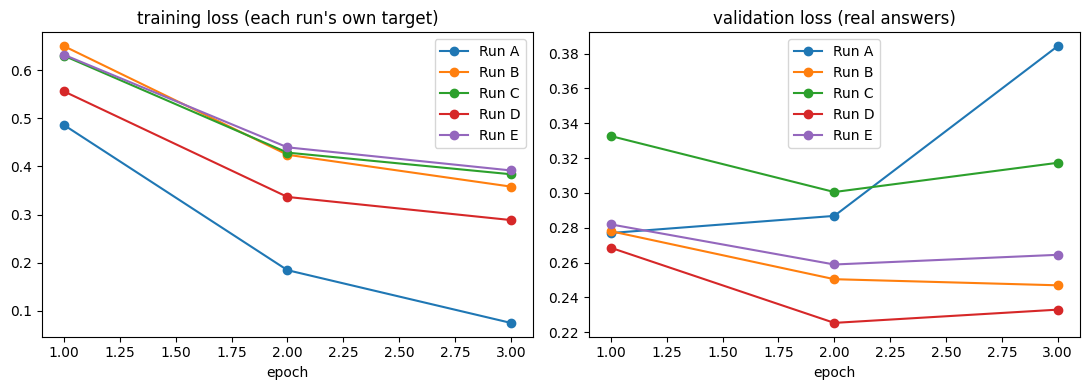

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for run in RUNS:
    h = pd.DataFrame(PREDS[run]["history"])
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", label=f"Run {run}")
    axes[1].plot(h["epoch"], h["val_loss"],   marker="o", label=f"Run {run}")
axes[0].set(title="training loss (each run's own target)", xlabel="epoch")
axes[1].set(title="validation loss (real answers)", xlabel="epoch")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150)
plt.show()

## **[21] — (Optional): install Laya**

In [ ]:
!pip install -q laya

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.0/113.0 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.5/380.5 kB 17.6 MB/s eta 0:00:00


## **[22] — (Optional): Laya as an outside reference**

In [ ]:
from laya import Router
router = Router()

def laya_chances(row):
    if row["type"] == "noul":
        q = {"d": {"type": "noul", "instructions": row["instructions"]}}
    else:
        q = {"d": {"type": "choice", "instructions": row["instructions"],
                   "criteria": {o: o for o in row["options"]}}}
    ans = router.predict(row["state"], q)["answers"]["d"]
    if row["type"] == "noul":
        p_true = ans.get("probability", ans.get("value"))
        if p_true is None:
            raise KeyError(f"Couldn't find the yes/no probability in Laya's answer: {ans}")
        return np.array([1.0 - float(p_true), float(p_true)])
    p = np.array([float(ans["probabilities"].get(o, 0.0)) for o in row["options"]])
    if p.sum() == 0:
        raise KeyError(f"Laya's option names didn't match: {ans}")
    return p / p.sum()

t0 = time.time()
PROBS["Laya"] = [laya_chances(r) for r in TEST]
print(f"Laya scored {len(TEST)} test questions in {time.time() - t0:.0f}s")
print({k: round(float(v), 3) for k, v in metrics(PROBS["Laya"], TEST).items()})